In [1]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Chemin vers le dossier data (le notebook est dans notebooks/, donc on remonte d'un niveau)
DATA_DIR = os.path.join("..", "data")

CLASSES = ["NORMAL", "PNEUMONIA"]
SPLITS = ["train", "validation", "test"]

for split in SPLITS:
    for cls in CLASSES:
        folder = os.path.join(DATA_DIR, split, cls)
        n_images = len([f for f in os.listdir(folder) if f.lower().endswith((".jpeg", ".jpg", ".png"))])
        print(f"{split}/{cls}: {n_images} images")

train/NORMAL: 1140 images
train/PNEUMONIA: 3294 images
validation/NORMAL: 201 images
validation/PNEUMONIA: 581 images
test/NORMAL: 234 images
test/PNEUMONIA: 390 images


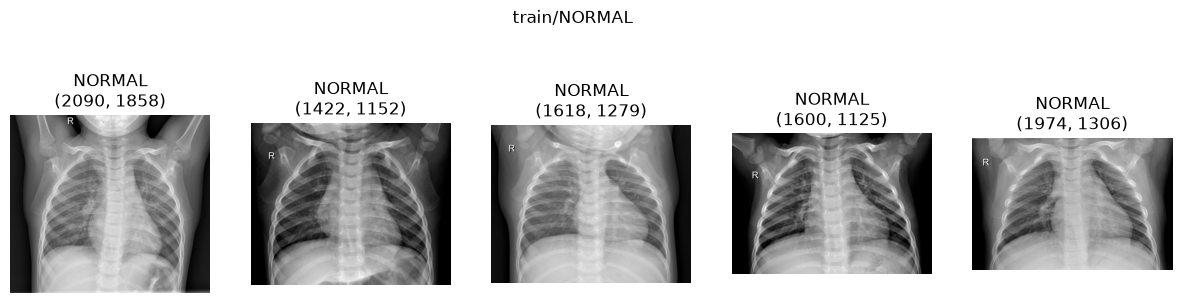

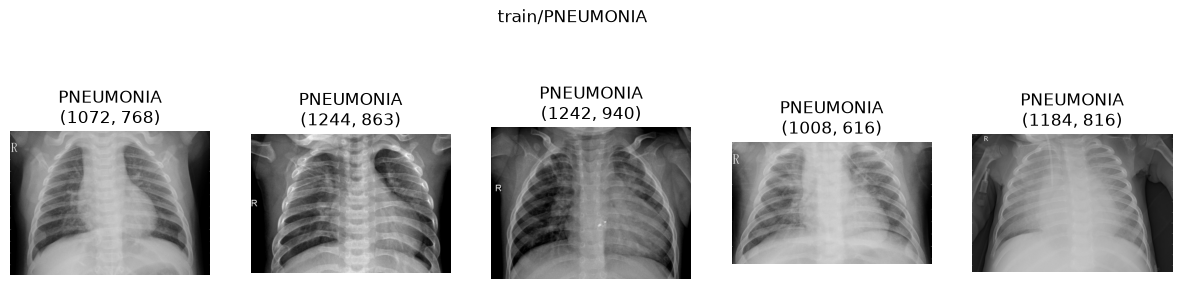

In [2]:
def show_examples(split, cls, n=5):
    folder = os.path.join(DATA_DIR, split, cls)
    images = [f for f in os.listdir(folder) if f.lower().endswith((".jpeg", ".jpg", ".png"))][:n]
    
    plt.figure(figsize=(15, 4))
    for i, img_name in enumerate(images):
        img_path = os.path.join(folder, img_name)
        img = Image.open(img_path)
        plt.subplot(1, n, i + 1)
        plt.imshow(img, cmap="gray")
        plt.title(f"{cls}\n{img.size}")
        plt.axis("off")
    plt.suptitle(f"{split}/{cls}")
    plt.show()

show_examples("train", "NORMAL")
show_examples("train", "PNEUMONIA")

In [3]:
import numpy as np

def check_image_mode(split, cls, n=5):
    folder = os.path.join(DATA_DIR, split, cls)
    images = [f for f in os.listdir(folder) if f.lower().endswith((".jpeg", ".jpg", ".png"))][:n]
    
    for img_name in images:
        img_path = os.path.join(folder, img_name)
        img = Image.open(img_path)
        arr = np.array(img)
        print(f"{img_name} — mode: {img.mode} — shape: {arr.shape}")

check_image_mode("train", "NORMAL")
check_image_mode("train", "PNEUMONIA")

IM-0115-0001.jpeg — mode: L — shape: (1858, 2090)
IM-0117-0001.jpeg — mode: L — shape: (1152, 1422)
IM-0122-0001.jpeg — mode: L — shape: (1279, 1618)
IM-0125-0001.jpeg — mode: L — shape: (1125, 1600)
IM-0127-0001.jpeg — mode: L — shape: (1306, 1974)
person1000_virus_1681.jpeg — mode: L — shape: (768, 1072)
person1001_bacteria_2932.jpeg — mode: L — shape: (863, 1244)
person1002_bacteria_2933.jpeg — mode: L — shape: (940, 1242)
person1003_virus_1685.jpeg — mode: L — shape: (616, 1008)
person1004_bacteria_2935.jpeg — mode: L — shape: (816, 1184)


In [4]:
from PIL import UnidentifiedImageError

def check_corrupted_images(split, cls):
    folder = os.path.join(DATA_DIR, split, cls)
    files = [f for f in os.listdir(folder) if f.lower().endswith((".jpeg", ".jpg", ".png"))]
    
    corrupted = []
    for img_name in files:
        img_path = os.path.join(folder, img_name)
        try:
            img = Image.open(img_path)
            img.verify()  # vérifie l'intégrité du fichier
        except (UnidentifiedImageError, OSError):
            corrupted.append(img_name)
    
    print(f"{split}/{cls}: {len(corrupted)} image(s) corrompue(s) sur {len(files)}")
    if corrupted:
        print("Fichiers corrompus:", corrupted)

for split in SPLITS:
    for cls in CLASSES:
        check_corrupted_images(split, cls)

train/NORMAL: 0 image(s) corrompue(s) sur 1140
train/PNEUMONIA: 0 image(s) corrompue(s) sur 3294
validation/NORMAL: 0 image(s) corrompue(s) sur 201
validation/PNEUMONIA: 0 image(s) corrompue(s) sur 581
test/NORMAL: 0 image(s) corrompue(s) sur 234
test/PNEUMONIA: 0 image(s) corrompue(s) sur 390


        split      class  count
0       train     NORMAL   1140
1       train  PNEUMONIA   3294
2  validation     NORMAL    201
3  validation  PNEUMONIA    581
4        test     NORMAL    234
5        test  PNEUMONIA    390


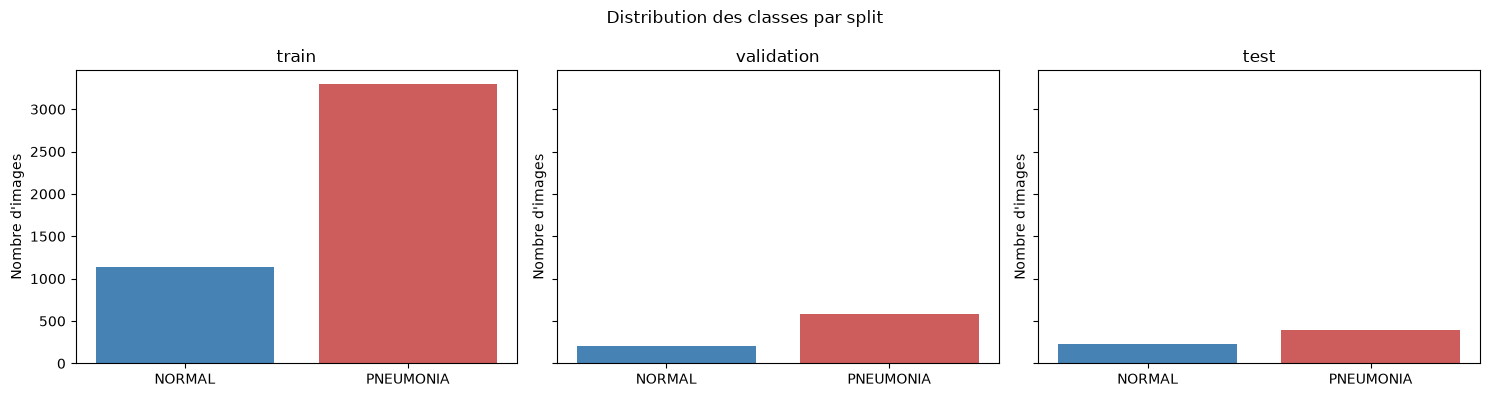

In [5]:
import pandas as pd

data_summary = []
for split in SPLITS:
    for cls in CLASSES:
        folder = os.path.join(DATA_DIR, split, cls)
        n_images = len([f for f in os.listdir(folder) if f.lower().endswith((".jpeg", ".jpg", ".png"))])
        data_summary.append({"split": split, "class": cls, "count": n_images})

df = pd.DataFrame(data_summary)
print(df)

# Graphique en barres
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, split in zip(axes, SPLITS):
    subset = df[df["split"] == split]
    ax.bar(subset["class"], subset["count"], color=["steelblue", "indianred"])
    ax.set_title(split)
    ax.set_ylabel("Nombre d'images")

plt.suptitle("Distribution des classes par split")
plt.tight_layout()
plt.show()